# Prototype De-stacking

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import galsim
import ultranest as un
from colossus.halo import profile_nfw
from colossus.cosmology import cosmology as colossus_cosmology

import astropy.units as u
from astropy.cosmology import FlatLambdaCDM, Planck18 
from astropy import constants
from astropy import table

from scipy import integrate
import xlensing
import cluster_toolkit
import glob

Lookup table loaded!


In [2]:
datadir = "/home/andre/data/TNG_SIMULATED_SHEAR_CATALOGS"

## Defining Units and scalings between codes

In [3]:
Mhalo = 1e14
conc = 5.
zhalo = .3
zsource = 1.0
OmegaM = 0.3
OmegaL = 0.7
astropy_cosmo = Planck18#FlatLambdaCDM(H0=.7,Om0=OmegaM)
galsim_cosmo = galsim.Cosmology()
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)

In [43]:
radii_mpc = np.linspace(0.01,10,1000)
ang_radii = np.degrees(radii_mpc/astropy_cosmo.angular_diameter_distance(.3).value)*3600
positions = [galsim.PositionD(0.,sep) for sep in ang_radii]

In [5]:
shears_galsim = np.array([halo.getShear(position,zsource) for position in positions])

In [6]:
def critical_surface_density(z_l, z_s, cosmo):
    """
    Calculates the critical surface density for gravitational lensing.

    Args:
        z_l (float): Redshift of the lensing galaxy.
        z_s (float): Redshift of the background source.
        cosmo (astropy.cosmology.Cosmology): The cosmological model to use.

    Returns:
        astropy.units.Quantity: The critical surface density.
    """
    # Define angular diameter distances
    D_l = cosmo.angular_diameter_distance(z_l)
    D_s = cosmo.angular_diameter_distance(z_s)
    D_ls = cosmo.angular_diameter_distance_z1z2(z_l, z_s)

    # Formula for the critical surface density
    numerator = (constants.c**2 * D_s)
    denominator = (4 * np.pi * constants.G * D_l * D_ls)
    sigma_crit = numerator / denominator

    # Convert to standard units for surface density (e.g., Msun / sq pc)
    return sigma_crit.to(u.M_sun / u.kpc**2)


# Define the redshifts for the lens and source
z_lens = 0.5   # Example lens redshift
z_source = 2.0 # Example source redshift

# Calculate the critical surface density
sigma_crit_value = critical_surface_density(z_lens, z_source, astropy_cosmo)

print(f"Lens redshift: {z_lens}")
print(f"Source redshift: {z_source}")
print(f"Critical surface density: {sigma_crit_value:.2e}")

# Example comparison: what if the lens is closer?
z_lens_closer = 0.25
sigma_crit_closer = critical_surface_density(z_lens_closer, z_source, astropy_cosmo)

print("\n--- Example with a closer lens ---")
print(f"Lens redshift: {z_lens_closer}")
print(f"Critical surface density: {sigma_crit_closer:.2e}")

Lens redshift: 0.5
Source redshift: 2.0
Critical surface density: 2.02e+09 solMass / kpc2

--- Example with a closer lens ---
Lens redshift: 0.25
Critical surface density: 2.48e+09 solMass / kpc2


In [7]:
def deltasigma_nfw_colossus(colossus_profile,z_source,r):
    z_lens = zhalo
    Sigma_bar = 2*(integrate.quad(lambda r : colossus_profile.surfaceDensity(r)*r,1e-5,r,epsabs=0.,limit=50))[0]/r**2
    Sigma = colossus_profile.surfaceDensity(r)
    deltasigma = Sigma_bar - Sigma
    return deltasigma/1e6

In [8]:
scrit=critical_surface_density(z_l=0.3, z_s=1.0, cosmo=astropy_cosmo).value/1e6

In [9]:
colossus_cosmology.setCosmology('planck18')
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')
delta_sigma_colossus=np.array([deltasigma_nfw_colossus(colossus_profile,1.,radius*1000) for radius in radii_mpc])

In [10]:
from cluster_toolkit import deltasigma

Sigma_nfw = deltasigma.Sigma_nfw_at_R(radii_mpc, mass=Mhalo, concentration=conc, Omega_m=OmegaM)
#shears_toolkit = deltasigma.DeltaSigma_at_R(radii_mpc, Rp, Sigma, Mass, concentartion, Omega_m)
delta_sigma_toolkit=deltasigma.DeltaSigma_at_R(
    R=radii_mpc,
    Rs=radii_mpc,
    Sigma=Sigma_nfw,
    mass=Mhalo,
    concentration=conc,
    Omega_m=OmegaM,
    delta=200,
)

In [11]:
xlensing_res=xlensing.model.NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)
delta_sigma_xlensing = xlensing_res['NFW Signal']

In [12]:
delta_sigma_galsim = shears_galsim[:,0]*scrit

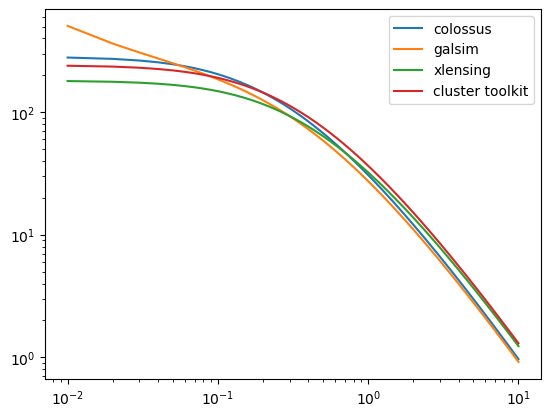

In [13]:
plt.plot(radii_mpc,delta_sigma_colossus,label='colossus')
plt.plot(radii_mpc,delta_sigma_galsim*Planck18.h,label='galsim')
plt.plot(radii_mpc,delta_sigma_xlensing/Planck18.h,label='xlensing')
plt.plot(radii_mpc,delta_sigma_toolkit/Planck18.h,label='cluster toolkit')

plt.xscale('log')
plt.yscale('log')
plt.legend()

In [14]:
radii_mpc = np.logspace(-2,1,10)

In [15]:
%%timeit
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')
delta_sigma_colossus=np.array([deltasigma_nfw_colossus(colossus_profile,1.,radius*1000) for radius in radii_mpc])

37.7 ms ± 2.59 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [16]:
%%timeit
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)
shears_galsim = np.array([halo.getShear(position,zsource) for position in positions])

89.5 ms ± 5.88 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [17]:
%%timeit
xlensing_res=xlensing.model.NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)

7.19 ms ± 475 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [18]:
%%timeit
Sigma_nfw = deltasigma.Sigma_nfw_at_R(radii_mpc, mass=Mhalo, concentration=conc, Omega_m=OmegaM)
#shears_toolkit = deltasigma.DeltaSigma_at_R(radii_mpc, Rp, Sigma, Mass, concentartion, Omega_m)
delta_sigma_toolkit=deltasigma.DeltaSigma_at_R(R=radii_mpc,Rs=radii_mpc,Sigma=Sigma_nfw,mass=Mhalo,concentration=conc,Omega_m=OmegaM,delta=200,
)

23.3 μs ± 2.58 μs per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


## Generating a field of galaxies

In [19]:
nbar = 30 

In [20]:
simplecat = xlensing.sims.make_simple_random_cat(nbar, width_rad=4./xlensing.cosmo.DA(0,zhalo), zrange=[0.2,1.0], shape_noise=0.25)
simplecat = table.Table(simplecat.T,names=['ra','dec','z','e1','e2','R11','R12','R21','R22','w'])

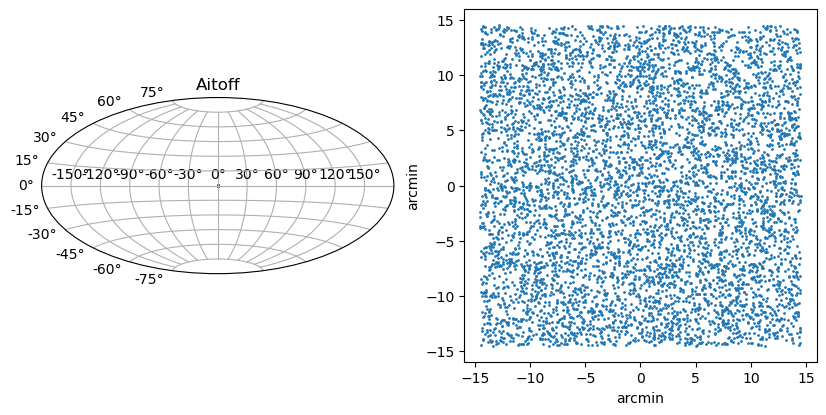

In [21]:
plt.figure(figsize=(10,5))
plt.subplot(121, projection="aitoff")
plt.scatter(simplecat['ra'],simplecat['dec'],s=1)
plt.title("Aitoff")
plt.grid(True)
plt.subplot(122)
plt.scatter(np.degrees(simplecat['ra'])*60,np.degrees(simplecat['dec'])*60,s=1)
plt.xlabel('arcmin')
plt.ylabel('arcmin')
ax = plt.gca()
ax.set_aspect('equal')

In [22]:
def simcluster(gal_density,total_radius,z_range,cluster,shape_noise,seed=31415):
    cat = xlensing.sims.make_simple_random_cat(
        density=gal_density, 
        width_rad=total_radius/xlensing.cosmo.DA(0,0.3), 
        zrange=z_range, 
        shape_noise=shape_noise,
        seed=seed
    ).T
    cat = xlensing.sims.apply_NFW_shear_region(cluster,cat)
    cat = table.Table(cat,names=['ra','dec','z','e1','e2','R11','R12','R21','R22','w'])
    return cat 

In [23]:
cluster = [0.,0.,.3,1e14,5.] 

In [24]:
cluster_test = simcluster(gal_density=30,total_radius=10,z_range=[.3,2.],cluster=cluster,shape_noise=0.000025)

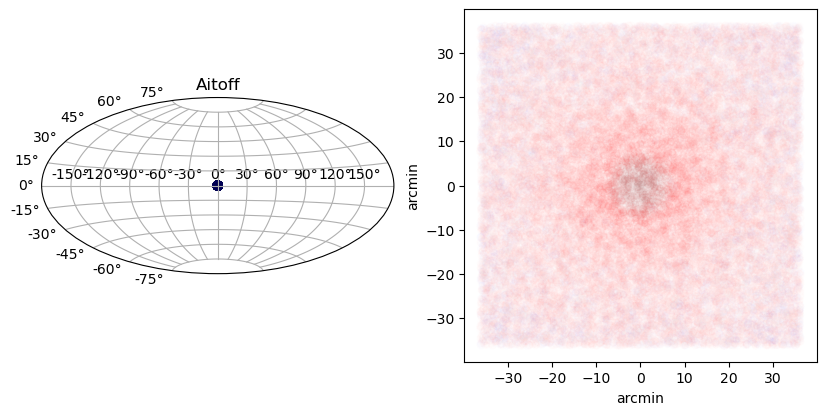

In [25]:
plt.figure(figsize=(10,5))
plt.subplot(121, projection="aitoff")
ellip = np.sqrt(cluster_test['e1']**2+ cluster_test['e2']**2)
plt.scatter(cluster_test['ra'],cluster_test['dec'],s=(cluster_test['z']+1)*10,c=ellip,cmap='seismic')
plt.title("Aitoff")
plt.grid(True)
plt.subplot(122)
plt.scatter(np.degrees(cluster_test['ra'])*60,np.degrees(cluster_test['dec'])*60,s=(cluster_test['z']+1)*10,c=np.log10(ellip),cmap='seismic',alpha=.01)
plt.xlabel('arcmin')
plt.ylabel('arcmin')
ax = plt.gca()
ax.set_aspect('equal')

In [45]:
cluster_test = simcluster(gal_density=30,total_radius=10,z_range=[.3,2.],cluster=cluster,shape_noise=0.25)

In [46]:
galaxy_catalog = {}
galaxy_catalog['RA'] = cluster_test['ra']
galaxy_catalog['DEC'] = cluster_test['dec']
galaxy_catalog['ZPHOT'] = cluster_test['z']
galaxy_catalog['E1'] = cluster_test['e1']
galaxy_catalog['E2'] = cluster_test['e2']
galaxy_catalog['WEIGHT'] =  np.ones_like(cluster_test['e1'])
galaxy_catalog['M'] = np.zeros_like(cluster_test['e1'])
galaxy_catalog = table.Table(galaxy_catalog)

## Fitting

In [47]:
clusters = table.Table([[0],[0],[0.3]],names=['RA','DEC', 'Z'])

In [48]:
sr_RA = np.array(galaxy_catalog['RA'])
sr_DEC= np.array(galaxy_catalog['DEC'])
sr_z  = np.array(galaxy_catalog['ZPHOT'])
sr_E1 = np.array(galaxy_catalog['E1'])
sr_E2 = np.array(galaxy_catalog['E2'])
sr_W = np.array(galaxy_catalog['WEIGHT'])
sr_M = np.array(galaxy_catalog['M'])

clusters['INDEX'] = np.array(range(len(clusters)))

In [49]:
galaxy_catalog

RA,DEC,ZPHOT,E1,E2,WEIGHT,M
float64,float64,float64,float64,float64,float64,float64
0.003075576578178741,-0.003999324870337749,1.531825945690484,0.2807474008513911,-0.0638133789758753,1.0,0.0
0.003694738202570649,-0.0050438853960828684,1.0309112683907382,-0.25021740933492215,-0.11075127588146491,1.0,0.0
0.009927993384140216,0.0023392854245808913,1.0126472053928728,0.23174208968444743,0.005918168938174722,1.0,0.0
0.008116215915429135,-0.00849480997228795,0.9316167201272343,0.09889041050110824,0.025392016395275337,1.0,0.0
0.008627934116884929,-0.01027487371006017,0.9516320447333853,-0.2608454648597909,0.0241441556853117,1.0,0.0
0.006825157475134489,0.000843786118978512,0.43872299027004746,-0.2298636241486173,-0.12935497181823027,1.0,0.0
-0.0002803158801636431,0.00750109200821094,0.30383429525918554,0.33264814942674037,0.07150730270831443,1.0,0.0
0.0025519721395205874,-0.0004962737717745854,0.6352758272551293,0.06220281771420871,-0.001571067381535714,1.0,0.0
0.0030269358806655194,-0.007440316921177774,0.7634607879445847,0.08841465405041846,0.1515028512509829,1.0,0.0


In [50]:
cl_RA=np.array(clusters['RA'])
cl_DEC= np.array(clusters['DEC'])
cl_z= np.array(clusters['Z'])
cl = np.array([cl_RA,cl_DEC,cl_z]).T

In [51]:
#let's use multiprocessing
from multiprocess import Pool, freeze_support, cpu_count
from functools import partial

# you can use whatever, but your machine core count is usually a good choice (although maybe not the best)
pool = Pool(cpu_count()) 

#We get a partial function with a constant galaxy catalogue to iterate with clusters.
survey_lensing = partial(xlensing.data.lensfit_cluster_lensing,sources=(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M),radius=10.)

In [52]:
clz = zip(cl_RA,cl_DEC,cl_z)
clzlist = [x for x in clz]

In [53]:
results = pool.map(survey_lensing, clzlist)

In [54]:
results

[{'Critical Density': array([2407.41596161, 2718.50271731, 2738.21655898, ..., 2283.8759268 ,
         2298.18339492, 3179.59598788]),
  'Tangential Shear': array([-0.13375647, -0.03013386,  0.20472269, ...,  0.00663931,
          0.07164993, -0.60509003]),
  'Cross Shear': array([ 0.25495187, -0.27196792, -0.1087568 , ...,  0.06150822,
         -0.51838413,  0.30240063]),
  'Radial Distance': array([4.78400942, 5.92869316, 9.67187271, ..., 4.62925246, 5.77901746,
         9.70119771]),
  'Polar Angle': array([-0.65556849, -0.63222279, -1.80219315, ...,  0.124059  ,
         -2.42600771, -1.91559642]),
  'Weights': array([1., 1., 1., ..., 1., 1., 1.]),
  'Mult. Bias': array([0., 0., 0., ..., 0., 0., 0.]),
  'Count': 28734}]

## Stacking

In [55]:
radii = np.logspace(-.8,.8,6)
N = len(radii)
bins_lims = np.logspace(np.log10(radii[0])+(np.log10(radii[0])-np.log10(radii[1]))/2,
                        np.log10(radii[N-1])-(np.log10(radii[0])-np.log10(radii[1]))/2,N+1)
bins_lims = np.array([[bins_lims[i],bins_lims[i+1]] for i in range(N)])
bins_lims #in Mpc/h

array([[0.10964782, 0.22908677],
       [0.22908677, 0.47863009],
       [0.47863009, 1.        ],
       [1.        , 2.08929613],
       [2.08929613, 4.36515832],
       [4.36515832, 9.12010839]])

In [56]:
stick = [clusters]

In [57]:
Nboot=500
import time
stick_results = []
for stake in stick:
    t = time.time()
    clusterbkgs = []
    for index in stake['INDEX']:
        Sigma_crit = np.array(results[index]['Critical Density'])
        e_t = np.array(results[index]['Tangential Shear'])
        e_x = np.array(results[index]['Critical Density'])
        W = np.array(results[index]['Weights'])
        M = np.array(results[index]['Mult. Bias'])
        R = np.array(results[index]['Radial Distance'])
        clusterbkgs.append(np.array([Sigma_crit, e_t, e_x, W, R,M]))
    print(len(clusterbkgs))
    #sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.stack(clusterbkgs,bins_lims,Nboot)
    #stick_results.append( ( sigmas, sigmas_cov, xigmas, xigmas_cov) )
    #print("Done in " + str(time.time()-t) + " seconds.")

1


In [58]:
sigmas, boosts, sigmas_cov, xigmas, xigmas_cov = xlensing.data.stacked_signal(clusterbkgs,bins_lims,Nboot)

Total galaxies available per bin:
[   10    55   239   996  4291 18403]



100%|███████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:00<00:00, 864.42it/s]


In [61]:
sigmas_cov

array([[ 7.30494684e-26, -1.08132437e-27,  4.61365063e-26,
         9.61177215e-27, -2.83547278e-26, -9.85206646e-27],
       [-1.08132437e-27,  1.60064462e-29, -6.82941706e-28,
        -1.42279522e-28,  4.19724590e-28,  1.45836510e-28],
       [ 4.61365063e-26, -6.82941706e-28,  2.91388461e-26,
         6.07059294e-27, -1.79082492e-26, -6.22235776e-27],
       [ 9.61177215e-27, -1.42279522e-28,  6.07059294e-27,
         1.26470686e-27, -3.73088524e-27, -1.29632453e-27],
       [-2.83547278e-26,  4.19724590e-28, -1.79082492e-26,
        -3.73088524e-27,  1.10061115e-26,  3.82415737e-27],
       [-9.85206646e-27,  1.45836510e-28, -6.22235776e-27,
        -1.29632453e-27,  3.82415737e-27,  1.32873265e-27]])

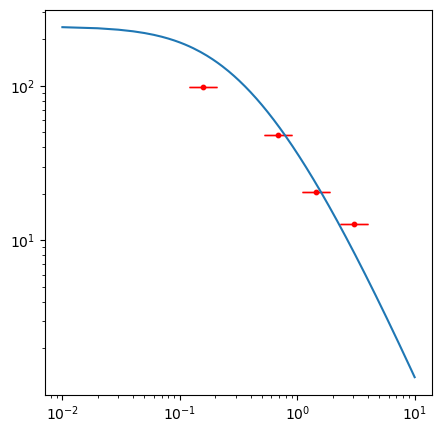

In [60]:
plt.figure(figsize=(5,5))
plt.scatter(radii,-np.array(sigmas),color='red',s=10)
plt.errorbar(radii,-np.array(sigmas),
             yerr=np.sqrt(np.diag(sigmas_cov)),
             fmt='.',color='red',markersize=.1,capsize=10,label='metacal shear')
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')
radii_mpc = np.linspace(0.01,10,1000)
plt.plot(radii_mpc,delta_sigma_toolkit/Planck18.h,label='cluster toolkit')